# Waiting on Alberta: Data Preparation
**Benchmarking Alberta's wait times for priority procedures against Canada, 2016–2025**

CRISP-DM Data Preparation steps: **Select Data → Clean Data → Construct Data → Integrate Data → Format Data → Dataset Description**.

In [ ]:
# openpyxl is the helper package that lets pandas open Excel (.xlsx) files.
%pip install pandas numpy matplotlib seaborn openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# Load the libraries:
# pandas for tables of data (rows and columns)
# numpy for number tools, including np.nan which means "missing value"
# matplotlib and seaborn for drawing charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Hide warning messages that do not affect the results, to keep the output easy to read.
import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Locating the files.
# '../' means "go up one folder" from the notebook folder to the main project folder.
# raw_data holds the original downloaded files; cleaned is where all prepared files are saved.
# raw_path=r'C:\Users\Owner\Desktop\OneDrive\Documents\Assignments\Capstone Project\Project\wait time alberta\raw_data\'
raw_path='../raw_data/'
cleaned_path='../cleaned/'

# Select Data
## CIHI wait times

In [ ]:
# Open the CIHI wait times file.
# This file was tidied by hand in Excel before loading: the extra sheets, the title row
# and the notes rows at the bottom were removed, so the column names are on row 1.
# Sheet_name='Table 1' tells pandas which sheet holds the data.
cihi=pd.read_excel(raw_path+'wait-times-priority-procedures-in-canada-2008-2025-data-tables-en.xlsx',
                   sheet_name='Table 1')

# Keep only the 8 data columns, chosen by name.
# This also drops a few stray cells typed to the right of the table (extra columns with no heading).
cihi_cols=['Reporting level','Province','Region','Indicator','Metric',
           'Data year','Unit of measurement','Indicator result']
cihi=cihi[cihi_cols]

# Explore the first 5 rows to check the data loaded correctly.
cihi.head()

,Reporting level,Province,Region,Indicator,Metric,Data year,Unit of measurement,Indicator result
0,Provincial,Alberta,NaN,Bladder Cancer Surgery,50th percentile,2008,Days,NaN
1,Provincial,Alberta,NaN,Bladder Cancer Surgery,90th percentile,2008,Days,NaN
2,Provincial,Alberta,NaN,Bladder Cancer Surgery,Volume,2008,Number of cases,NaN
3,Provincial,Alberta,NaN,Breast Cancer Surgery,50th percentile,2008,Days,NaN
4,Provincial,Alberta,NaN,Breast Cancer Surgery,90th percentile,2008,Days,NaN


In [5]:
# Summary of the table: number of rows, column names, data types,
# and how many values are filled in (not missing) in each column.
cihi.info()

<class 'pandas.DataFrame'>
RangeIndex: 20500 entries, 0 to 20499
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Reporting level      20500 non-null  str    
 1   Province             20500 non-null  str    
 2   Region               5576 non-null   str    
 3   Indicator            20500 non-null  str    
 4   Metric               20500 non-null  str    
 5   Data year            20500 non-null  object 
 6   Unit of measurement  20500 non-null  str    
 7   Indicator result     16208 non-null  float64
dtypes: float64(1), object(1), str(6)
memory usage: 1.3+ MB


In [6]:
# Quick statistics for every column: counts, number of unique values,
# most common value, and for numbers the mean, minimum and maximum.
cihi.describe(include='all')

,Reporting level,Province,Region,Indicator,Metric,Data year,Unit of measurement,Indicator result
count,20500,20500,5576,20500,20500,20500.0,20500,1.620800e+04
unique,3,11,59,14,4,30.0,4,NaN
top,Provincial,Quebec,South Zone,Hip Replacement,50th percentile,2025.0,Days,NaN
freq,13576,3076,96,4108,5774,1000.0,10708,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.023876e+03
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.535811e+04
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000e+00
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.800000e+01
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000e+02
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.560000e+02


## Select the rows needed for the business questions

In [ ]:
# Finding out how many rows exist at each reporting level?
# National = Canada (our benchmark), Provincial = each province, Regional = health regions.
cihi['Reporting level'].value_counts()

Reporting level
Provincial    13576
Regional       5576
National       1348
Name: count, dtype: int64

In [ ]:
# Which reporting periods exists?
# A plain year (e.g. 2023) means April to September of that year.
# 'FY' (full fiscal year) and 'Q3Q4' (October to March) are extra periods CIHI added during COVID.
cihi['Data year'].value_counts()

Data year
2025        1000
2014         992
2015         992
2016         992
2017         992
2018         992
2019         992
2020         992
2021         992
2022         992
2023         992
2024         992
2008         539
2009         539
2010         539
2011         539
2012         528
2013         528
2019FY       448
2019Q3Q4     448
2020FY       448
2020Q3Q4     448
2021FY       448
2021Q3Q4     448
2022FY       448
2022Q3Q4     448
2023FY       448
2023Q3Q4     448
2024FY       448
2024Q3Q4     448
Name: count, dtype: int64

In [9]:
# Which procedures are in the file, and how many rows does each have?
cihi['Indicator'].value_counts()

Indicator
Hip Replacement                                4108
Knee Replacement                               4108
Cataract Surgery                               1320
Radiation Therapy                              1320
CABG                                           1034
Bladder Cancer Surgery                          990
Breast Cancer Surgery                           990
Colorectal Cancer Surgery                       990
CT Scan                                         990
Lung Cancer Surgery                             990
MRI Scan                                        990
Prostate Cancer Surgery                         990
Hip Fracture Repair/Emergency and Inpatient     888
Hip Fracture Repair                             792
Name: count, dtype: int64

In [ ]:
# Keeping only the rows this project needs:
# 1) Provincial and National rows (regional data exists only for hip and knee, so it is left out).
# 2) The 10-year period 2016-2025, plain April-September years only, so every year is measured the same.
#    The list below is built with a list comprehension: it creates '2016', '2017', ... '2025'.
# 3) The 5 procedures that have a national benchmark (a target maximum wait time).
years=[str(i) for i in range(2016,2026)]
procedures=['Hip Replacement','Knee Replacement','Cataract Surgery',
            'Radiation Therapy','Hip Fracture Repair']

cihi=cihi[
    (cihi['Reporting level'].isin(['Provincial','National'])) &
    (cihi['Data year'].astype(str).isin(years)) &
    (cihi['Indicator'].isin(procedures))
]

# Show the number of rows and columns left: 11 places x 5 procedures x 4 measures x 10 years = 2,200 rows.
print(cihi.shape)

(2200, 8)


In [11]:
# Check the selection: each place, procedure and measure should appear an equal number of times.
print(cihi['Province'].value_counts())
print(cihi['Indicator'].value_counts())
print(cihi['Metric'].value_counts())

Province
Alberta                      200
British Columbia             200
Canada                       200
Manitoba                     200
New Brunswick                200
Newfoundland and Labrador    200
Nova Scotia                  200
Ontario                      200
Prince Edward Island         200
Quebec                       200
Saskatchewan                 200
Name: count, dtype: int64
Indicator
Cataract Surgery       440
Hip Fracture Repair    440
Hip Replacement        440
Knee Replacement       440
Radiation Therapy      440
Name: count, dtype: int64
Metric
% meeting benchmark    550
50th percentile        550
90th percentile        550
Volume                 550
Name: count, dtype: int64


## Statistics Canada population estimates

In [ ]:
# Explore the first 5 rows.
# It was already filtered on the StatCan website to Canada + 10 provinces,
# total of all genders, and 3 measures: total population, people aged 65+, and median age.
pop=pd.read_csv(raw_path+'statcan_1710000501_pop_est.csv')
pop.head()

,REF_DATE,GEO,DGUID,Gender,Age group,UOM,UOM_ID,SCALAR_FACTOR,SCALAR_ID,VECTOR,COORDINATE,VALUE,STATUS,SYMBOL,TERMINATED,DECIMALS
0,2008,Canada,2021A000011124,Total - gender,All ages,Persons,249,units,0,v466668,1.1.1,33247298.0,NaN,NaN,NaN,0
1,2009,Canada,2021A000011124,Total - gender,All ages,Persons,249,units,0,v466668,1.1.1,33630069.0,NaN,NaN,NaN,0
2,2010,Canada,2021A000011124,Total - gender,All ages,Persons,249,units,0,v466668,1.1.1,34005902.0,NaN,NaN,NaN,0
3,2011,Canada,2021A000011124,Total - gender,All ages,Persons,249,units,0,v466668,1.1.1,34339221.0,NaN,NaN,NaN,0
4,2012,Canada,2021A000011124,Total - gender,All ages,Persons,249,units,0,v466668,1.1.1,34713395.0,NaN,NaN,NaN,0


In [16]:
# Summary of the population table: rows, columns, data types and missing values.
pop.info()

<class 'pandas.DataFrame'>
RangeIndex: 594 entries, 0 to 593
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   REF_DATE       594 non-null    int64  
 1   GEO            594 non-null    str    
 2   DGUID          594 non-null    str    
 3   Gender         594 non-null    str    
 4   Age group      594 non-null    str    
 5   UOM            594 non-null    str    
 6   UOM_ID         594 non-null    int64  
 7   SCALAR_FACTOR  594 non-null    str    
 8   SCALAR_ID      594 non-null    int64  
 9   VECTOR         594 non-null    str    
 10  COORDINATE     594 non-null    str    
 11  VALUE          594 non-null    float64
 12  STATUS         0 non-null      float64
 13  SYMBOL         0 non-null      float64
 14  TERMINATED     0 non-null      float64
 15  DECIMALS       594 non-null    int64  
dtypes: float64(4), int64(4), str(8)
memory usage: 74.4 KB


In [17]:
# Keep the same 10 years as the wait time data (2016 to 2025).
pop=pop[(pop['REF_DATE']>=2016) & (pop['REF_DATE']<=2025)]

# Keep only the 4 useful columns; the others are StatCan reference codes.
# REF_DATE = year, GEO = province or Canada, Age group = which measure, VALUE = the number.
pop=pop[['REF_DATE','GEO','Age group','VALUE']]

# 11 places x 10 years x 3 measures = 330 rows.
print(pop.shape)
print(pop['Age group'].value_counts())

(330, 4)
Age group
All ages              110
65 years and older    110
Median age            110
Name: count, dtype: int64


# Data Cleaning
## Duplicates

In [18]:
# Count rows that are exact copies of another row. Duplicates would count the same result twice.
print("CIHI duplicates:",cihi.duplicated().sum())
print("StatCan duplicates:",pop.duplicated().sum())

CIHI duplicates: 0
StatCan duplicates: 0


## Missing values

In [19]:
# Count the empty (missing) values in each column.
cihi.isnull().sum()

Reporting level           0
Province                  0
Region                 2200
Indicator                 0
Metric                    0
Data year                 0
Unit of measurement       0
Indicator result         60
dtype: int64

In [20]:
# 'Region' is always empty for provincial and national rows, so it carries no information.
# 'Reporting level' is no longer needed now that only provincial and national rows remain.
cihi=cihi.drop(columns=['Reporting level','Region'])

In [ ]:
# Find out where the missing results are: keep only rows with a missing result,
# then count them by province and procedure in a cross-table.
missing=cihi[cihi['Indicator result'].isnull()]
print(len(missing),"missing results out of",len(cihi))
pd.crosstab(missing['Province'],missing['Indicator'])

60 missing results out of 2200


Indicator,Hip Fracture Repair,Radiation Therapy
Province,,
Quebec,40,20


In [22]:
# Count the missing results by procedure and measure, to see exactly which measures are not reported.
# Finding: all 60 missing values are Quebec. Quebec does not report hip fracture repair at all (40 values)
# and does not report radiation therapy median and 90th-percentile waits (20 values).
# Decision: the missing values are NOT filled in. They are the results we want to study,
# so guessing them would bias the analysis. These Quebec rows are left out of any model that needs them.
pd.crosstab(missing['Indicator'],missing['Metric'])

Metric,% meeting benchmark,50th percentile,90th percentile,Volume
Indicator,,,,
Hip Fracture Repair,10,10,10,10
Radiation Therapy,0,10,10,0


In [ ]:
# Check the population table for missing values.
pop.isnull().sum()

REF_DATE     0
GEO          0
Age group    0
VALUE        0
dtype: int64

## Data types and units

In [ ]:
# 'Data year' is stored as text (because the file also had labels like '2019FY').
# Converting it to a whole number in a new column called 'Year', so it can be used in calculations.
cihi['Year']=cihi['Data year'].astype(int)
cihi=cihi.drop(columns=['Data year'])

# Show which units are used. Hip fracture repair waits are in Hours; other waits are in Days.
cihi['Unit of measurement'].value_counts()

Unit of measurement
Days               880
Proportion         550
Number of cases    550
Hours              220
Name: count, dtype: int64

In [ ]:
# Convert hip fracture repair waits from hours to days (hours / 24),
# so that all wait times use the same unit and can be compared and modelled together.
# 'hours' is a True/False list marking the rows measured in hours;
# .loc[hours, column] changes only those rows in that column.
hours=cihi['Unit of measurement']=='Hours'
cihi.loc[hours,'Indicator result']=cihi.loc[hours,'Indicator result']/24
cihi.loc[hours,'Unit of measurement']='Days'

# Check: there shouldn't be any 'Hours' left.
cihi['Unit of measurement'].value_counts()

Unit of measurement
Days               1100
Proportion          550
Number of cases     550
Name: count, dtype: int64

In [26]:
# The unit column is no longer needed: the column names created next will say the unit.
cihi=cihi.drop(columns=['Unit of measurement'])
cihi.head()

,Province,Indicator,Metric,Indicator result,Year
5205,Alberta,Cataract Surgery,% meeting benchmark,58.0,2016
5206,Alberta,Cataract Surgery,50th percentile,92.0,2016
5207,Alberta,Cataract Surgery,90th percentile,243.0,2016
5208,Alberta,Cataract Surgery,Volume,11770.0,2016
5215,Alberta,Hip Fracture Repair,% meeting benchmark,91.0,2016


# Construct Data
## One row per province, procedure and year

In [ ]:
# At the moment, each of the 4 measures is on its own:
#   % meeting benchmark, 50th percentile (median wait), 90th percentile wait, and Volume.
# For analysis we want ONE row per province, procedure and year, with the 4 measures side by side.
# Step 1: take each measure separately and rename 'Indicator result' to a clear column name.
keys=['Province','Indicator','Year']

pct=(cihi[cihi['Metric']=='% meeting benchmark'][keys+['Indicator result']]
     .rename(columns={'Indicator result':'Pct_Within_Benchmark'}))
p50=(cihi[cihi['Metric']=='50th percentile'][keys+['Indicator result']]
     .rename(columns={'Indicator result':'Median_Days'}))
p90=(cihi[cihi['Metric']=='90th percentile'][keys+['Indicator result']]
     .rename(columns={'Indicator result':'P90_Days'}))
vol=(cihi[cihi['Metric']=='Volume'][keys+['Indicator result']]
     .rename(columns={'Indicator result':'Volume'}))

# Step 2: join the 4 small tables side by side, matching on province, procedure and year.
# pd.merge lines up rows that share the same keys (like VLOOKUP in Excel).
# how='outer' keeps every row even if one measure is missing, so no data is lost.
waits=pd.merge(pct,p50,on=keys,how='outer')
waits=pd.merge(waits,p90,on=keys,how='outer')
waits=pd.merge(waits,vol,on=keys,how='outer')

# 11 places x 5 procedures x 10 years = 550 rows.
print(waits.shape)
waits.head()

(550, 7)


,Province,Indicator,Year,Pct_Within_Benchmark,Median_Days,P90_Days,Volume
0,Alberta,Cataract Surgery,2016,58.0,92.0,243.0,11770.0
1,Alberta,Cataract Surgery,2017,55.6,99.0,260.0,11389.0
2,Alberta,Cataract Surgery,2018,48.7,116.0,320.0,11684.0
3,Alberta,Cataract Surgery,2019,44.3,131.0,356.0,13409.0
4,Alberta,Cataract Surgery,2020,34.6,183.0,396.0,10424.0


## Population table: one row per province and year

In [ ]:
# Same idea here: put the 3 measures side by side.
# Step 1: take each measure separately and give it a clear name.
all_ages=(pop[pop['Age group']=='All ages'][['GEO','REF_DATE','VALUE']]
          .rename(columns={'VALUE':'Population'}))
age65=(pop[pop['Age group']=='65 years and older'][['GEO','REF_DATE','VALUE']]
       .rename(columns={'VALUE':'Population_65plus'}))
med_age=(pop[pop['Age group']=='Median age'][['GEO','REF_DATE','VALUE']]
         .rename(columns={'VALUE':'Median_Age'}))

# Step 2: join them on place and year.
population=pd.merge(all_ages,age65,on=['GEO','REF_DATE'])
population=pd.merge(population,med_age,on=['GEO','REF_DATE'])

# Rename the StatCan column names to match the CIHI names, so the two tables can be joined later.
population=population.rename(columns={'GEO':'Province','REF_DATE':'Year'})

# 11 places x 10 years = 110 rows.
print(population.shape)
population.head()

(110, 5)


,Province,Year,Population,Population_65plus,Median_Age
0,Canada,2016,36110803.0,5919685.0,40.7
1,Canada,2017,36545075.0,6125483.0,40.8
2,Canada,2018,37072620.0,6337440.0,40.7
3,Canada,2019,37618495.0,6573259.0,40.7
4,Canada,2020,38028638.0,6809521.0,40.8


# Integrate Data
## Join wait times with population

In [29]:
# Check that both tables contain the same 11 places (names are spelled the same in both sources).
print(waits['Province'].nunique(),population['Province'].nunique())

# Add the population numbers to every wait time row, matching on province and year.
# how='left' keeps all 550 wait time rows.
data=pd.merge(waits,population,on=['Province','Year'],how='left')
print(data.shape)

# Every row should have found its population (0 rows without population).
print(data['Population'].isnull().sum(),"rows without population")

11 11
(550, 10)
0 rows without population


## Add Canada's result as the benchmark for every row

In [30]:
# Canada is the benchmark. To compare each province with Canada, we copy Canada's result
# for the same procedure and year onto every province row.
# Step 1: take Canada's rows and rename the columns so they are clearly Canada's values.
canada=(data[data['Province']=='Canada'][['Indicator','Year','Pct_Within_Benchmark','Median_Days','P90_Days']]
        .rename(columns={'Pct_Within_Benchmark':'Canada_Pct',
                         'Median_Days':'Canada_Median_Days',
                         'P90_Days':'Canada_P90_Days'}))

# Step 2: attach them to every row with the same procedure and year.
data=pd.merge(data,canada,on=['Indicator','Year'],how='left')
data.head()

,Province,Indicator,Year,Pct_Within_Benchmark,Median_Days,P90_Days,Volume,Population,Population_65plus,Median_Age,Canada_Pct,Canada_Median_Days,Canada_P90_Days
0,Alberta,Cataract Surgery,2016,58.0,92.0,243.0,11770.0,4195427.0,502101.0,36.3,72.491813,67.611193,193.559332
1,Alberta,Cataract Surgery,2017,55.6,99.0,260.0,11389.0,4237310.0,524103.0,36.6,70.890038,65.709563,210.707453
2,Alberta,Cataract Surgery,2018,48.7,116.0,320.0,11684.0,4292556.0,548657.0,36.9,70.103064,65.356385,217.602114
3,Alberta,Cataract Surgery,2019,44.3,131.0,356.0,13409.0,4355377.0,577725.0,37.2,70.413238,67.048136,219.291734
4,Alberta,Cataract Surgery,2020,34.6,183.0,396.0,10424.0,4407495.0,606936.0,37.5,44.859871,133.348483,309.577486


## Derived attributes (new columns)

In [ ]:
# Creating new columns that makes provinces of different sizes comparable:
# Volume_per_100k: procedures done per 100,000 people (a fair measure of capacity,
#                  because a big province naturally does more procedures than a small one).
# Pct_65plus: share of the population aged 65 and older, in percent (a measure of ageing).
data['Volume_per_100k']=data['Volume']/data['Population']*100000
data['Pct_65plus']=data['Population_65plus']/data['Population']*100

# COVID_Flag: 1 for the COVID years 2020 and 2021, 0 for other years,
# so the models can account for the disruption COVID caused.
data['COVID_Flag']=data['Year'].isin([2020,2021]).astype(int)

In [ ]:
# Period: label each year as Pre-COVID (2016-2019), COVID (2020-2021) or Recovery (2022-2025).
# Using if / elif / else decides the label for one year,
# and .apply() runs that function on every row.
def period(year):
    if year<2020:
        return 'Pre-COVID'
    elif year<=2021:
        return 'COVID'
    else:
        return 'Recovery'

data['Period']=data['Year'].apply(period)
data['Period'].value_counts()

Period
Pre-COVID    220
Recovery     220
COVID        110
Name: count, dtype: int64

In [33]:
# Gap columns: how far each province is from Canada for the same procedure and year.
# Gap_Pct_vs_Canada: percentage points of patients treated on time, province minus Canada
#                    (negative = worse than Canada).
# Gap_P90_vs_Canada: extra days of 90th-percentile wait, province minus Canada
#                    (positive = longer wait than Canada).
data['Gap_Pct_vs_Canada']=data['Pct_Within_Benchmark']-data['Canada_Pct']
data['Gap_P90_vs_Canada']=data['P90_Days']-data['Canada_P90_Days']

In [ ]:
# Meets_Canada: the yes/no answer the KNN model will learn to predict (business question 2).
# 1 = the province treated the same or a higher share of patients on time than Canada, 0 = lower.
# Starting with every row as missing (np.nan), then fill in 1 or 0 only where the province
# actually reported a result. Otherwise a missing result would wrongly be counted as 0.
# '~' means "not": ~...isnull() means "is not missing".
data['Meets_Canada']=np.nan
has_pct=~data['Pct_Within_Benchmark'].isnull()
data.loc[has_pct,'Meets_Canada']=(data.loc[has_pct,'Pct_Within_Benchmark']>=data.loc[has_pct,'Canada_Pct']).astype(int)

# Show Alberta's first 10 rows to check the new columns.
data[data['Province']=='Alberta'].head(10)

,Province,Indicator,Year,Pct_Within_Benchmark,Median_Days,P90_Days,Volume,Population,Population_65plus,Median_Age,Canada_Pct,Canada_Median_Days,Canada_P90_Days,Volume_per_100k,Pct_65plus,COVID_Flag,Period,Gap_Pct_vs_Canada,Gap_P90_vs_Canada,Meets_Canada
0,Alberta,Cataract Surgery,2016,58.0,92.0,243.0,11770.0,4195427.0,502101.0,36.3,72.491813,67.611193,193.559332,280.543554,11.967816,0,Pre-COVID,-14.491813,49.440668,0.0
1,Alberta,Cataract Surgery,2017,55.6,99.0,260.0,11389.0,4237310.0,524103.0,36.6,70.890038,65.709563,210.707453,268.779013,12.368767,0,Pre-COVID,-15.290038,49.292547,0.0
2,Alberta,Cataract Surgery,2018,48.7,116.0,320.0,11684.0,4292556.0,548657.0,36.9,70.103064,65.356385,217.602114,272.192139,12.781592,0,Pre-COVID,-21.403064,102.397886,0.0
3,Alberta,Cataract Surgery,2019,44.3,131.0,356.0,13409.0,4355377.0,577725.0,37.2,70.413238,67.048136,219.291734,307.872315,13.264638,0,Pre-COVID,-26.113238,136.708266,0.0
4,Alberta,Cataract Surgery,2020,34.6,183.0,396.0,10424.0,4407495.0,606936.0,37.5,44.859871,133.348483,309.577486,236.506224,13.770543,1,COVID,-10.259871,86.422514,0.0
5,Alberta,Cataract Surgery,2021,63.6,75.0,266.0,15658.0,4431531.0,636049.0,37.9,66.042346,71.943542,255.609106,353.331614,14.352805,1,COVID,-2.442346,10.390894,0.0
6,Alberta,Cataract Surgery,2022,65.5,75.0,259.0,12372.0,4513589.0,668218.0,38.1,65.466035,73.237508,275.875822,274.105595,14.804582,0,Recovery,0.033965,-16.875822,1.0
7,Alberta,Cataract Surgery,2023,61.0,90.0,244.0,14342.0,4688032.0,705105.0,38.1,69.584338,66.268885,241.048038,305.927946,15.040533,0,Recovery,-8.584338,2.951962,0.0
8,Alberta,Cataract Surgery,2024,62.8,85.0,249.0,16895.0,4901795.0,742312.0,37.9,68.952362,67.834441,229.189086,344.669657,15.143677,0,Recovery,-6.152362,19.810914,0.0
9,Alberta,Cataract Surgery,2025,66.0,72.0,274.0,16874.0,5024631.0,779088.0,38.1,69.677240,66.408943,222.829010,335.825656,15.505377,0,Recovery,-3.677240,51.170990,0.0


# Exploratory checks on the prepared data

In [35]:
# For the checks below we use only the 10 provinces.
# Canada is the benchmark the provinces are compared against, not one of the cases.
prov=data[data['Province']!='Canada']
print(prov.shape)

(500, 20)


Text(0.5, 1.0, 'Province results at or above Canada (1) vs below (0)')

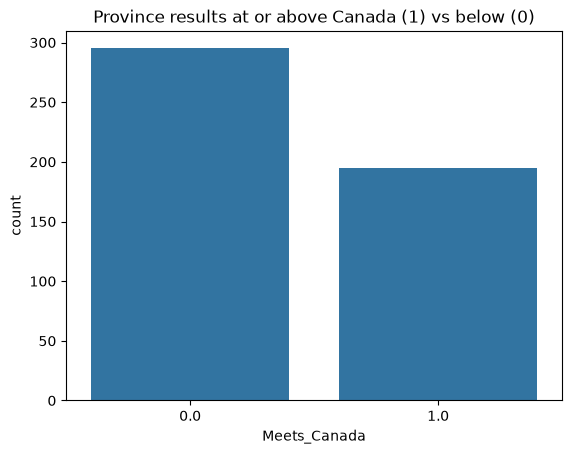

In [36]:
# Bar chart counting how often provinces were at/above Canada (1) or below Canada (0).
# This shows whether the KNN target is balanced (not almost all 0s or all 1s).
sns.countplot(x='Meets_Canada',data=prov)
plt.title('Province results at or above Canada (1) vs below (0)')

In [37]:
# The same counts shown as proportions (shares of the total).
prov['Meets_Canada'].value_counts(normalize=True)

Meets_Canada
0.0    0.602041
1.0    0.397959
Name: proportion, dtype: float64

Text(0.5, 1.0, '90th-percentile Wait (days) by Procedure, 2016-2025')

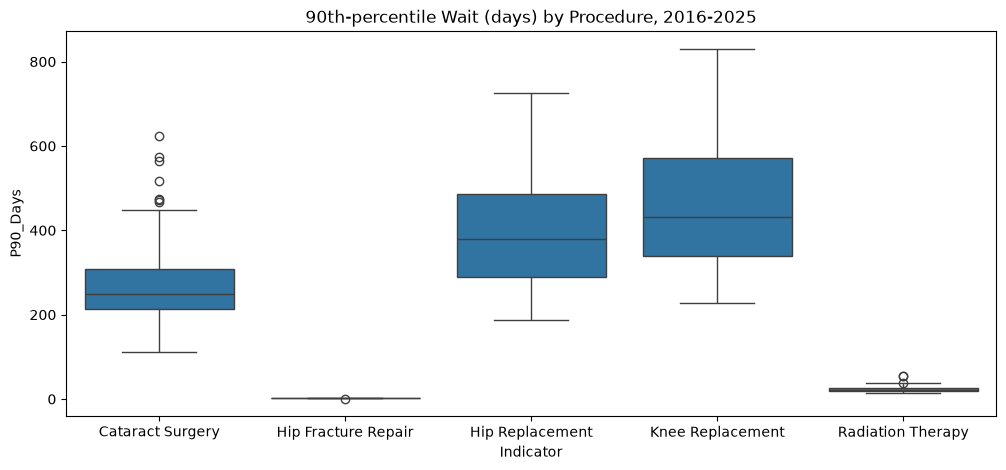

In [38]:
# Box plot of the 90th-percentile wait (the regression target) for each procedure.
# The box shows where the middle half of values fall; dots beyond the whiskers are unusual values (outliers).
plt.figure(figsize=(12,5))
sns.boxplot(x='Indicator',y='P90_Days',data=prov)
plt.title('90th-percentile Wait (days) by Procedure, 2016-2025')

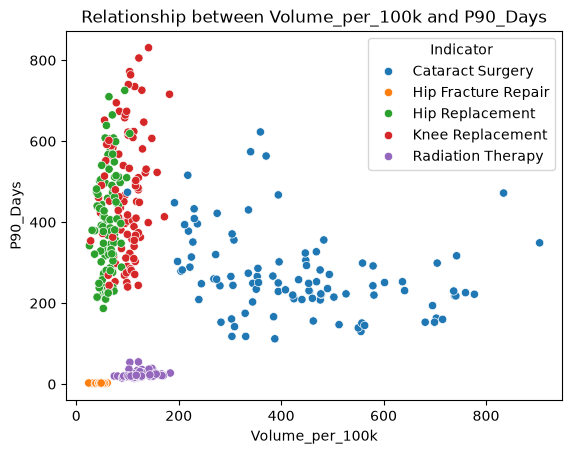

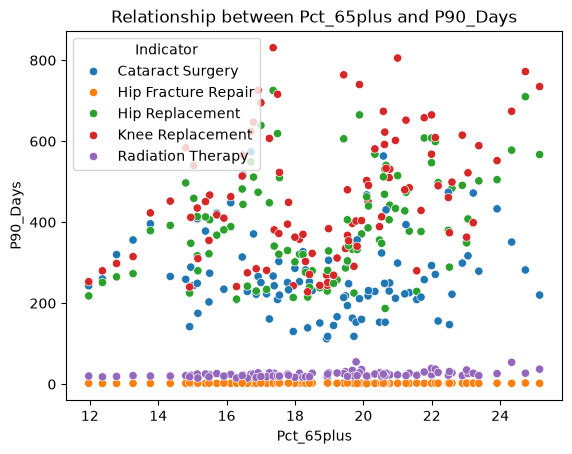

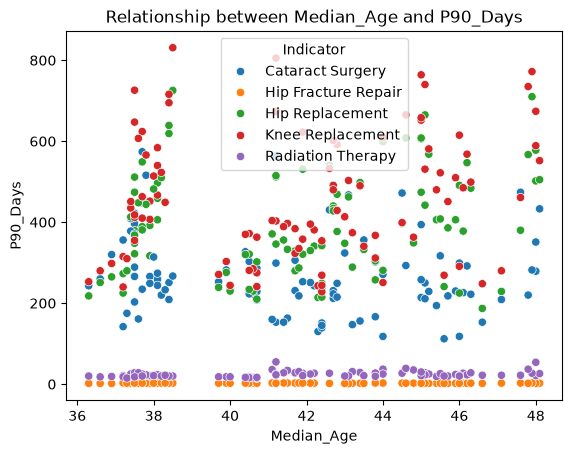

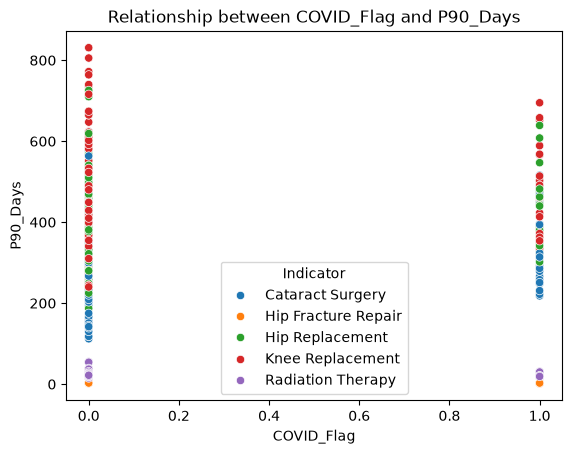

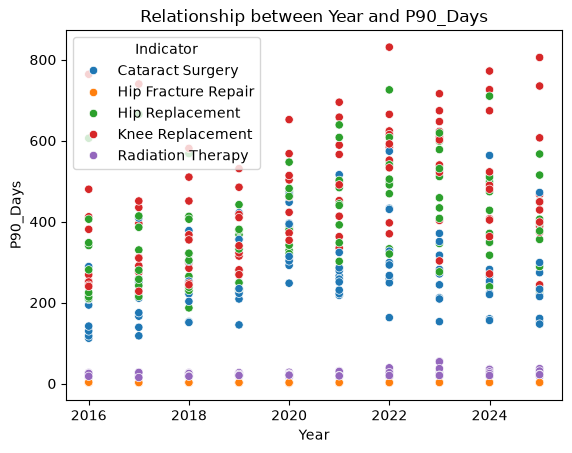

In [39]:
# Scatter plots: does the 90th-percentile wait change as each feature changes?
# The loop draws one chart per feature; colours show the procedure.
num_cols=['P90_Days','Volume_per_100k','Pct_65plus','Median_Age','COVID_Flag','Year']

for i in num_cols[1:]:
  sns.scatterplot(x=i,y='P90_Days',hue='Indicator',data=prov)
  plt.title(f"Relationship between {i} and P90_Days")
  plt.show()

<Axes: >

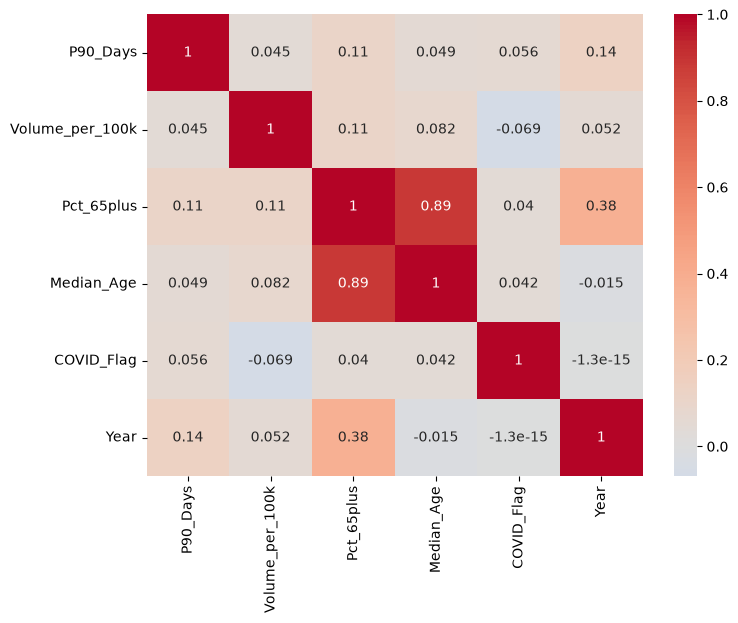

In [40]:
# Correlation heat map: a number from -1 to 1 for every pair of columns.
# Close to 1 = they rise together; close to -1 = one rises as the other falls; near 0 = no straight-line link.
corr_matrix=prov[num_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",center=0)

In [41]:
# For each province: the share of results below Canada (0) and at/above Canada (1).
# normalize='index' turns counts into shares that add up to 1 for each province.
prop=pd.crosstab(prov['Province'],prov['Meets_Canada'],normalize='index')
print(prop)

Meets_Canada                0.0   1.0
Province                             
Alberta                    0.50  0.50
British Columbia           0.72  0.28
Manitoba                   0.60  0.40
New Brunswick              0.72  0.28
Newfoundland and Labrador  0.50  0.50
Nova Scotia                0.72  0.28
Ontario                    0.32  0.68
Prince Edward Island       0.70  0.30
Quebec                     0.45  0.55
Saskatchewan               0.76  0.24


<Axes: xlabel='Meets_Canada', ylabel='Province'>

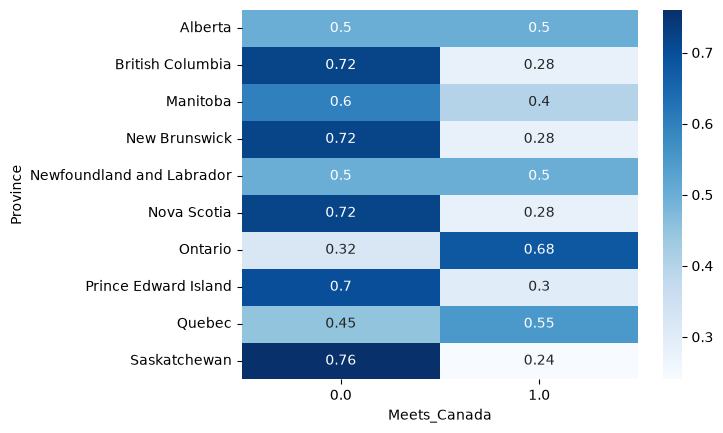

In [42]:
# The same table as a colour-shaded heat map, so the strongest and weakest provinces stand out.
sns.heatmap(prop,annot=True,cmap="Blues")

In [43]:
# Alberta's average gap from Canada for each procedure over the 10 years.
# Negative Gap_Pct = fewer patients treated on time than Canada; positive Gap_P90 = longer waits than Canada.
data[data['Province']=='Alberta'].groupby('Indicator')[['Gap_Pct_vs_Canada','Gap_P90_vs_Canada']].mean()

,Gap_Pct_vs_Canada,Gap_P90_vs_Canada
Indicator,,
Cataract Surgery,-10.838035,49.171082
Hip Fracture Repair,5.595830,-0.394382
Hip Replacement,-5.591393,20.766996
Knee Replacement,-6.870356,28.681021
Radiation Therapy,1.954585,-1.135458


# Format Data
## Model-ready dataset (provinces only)

In [44]:
# Build the dataset the models will use: provinces only (Canada is the benchmark).
model_data=data[data['Province']!='Canada']

# Models need numbers, but 'Indicator' (the procedure name) is text.
# Following the course approach (is_married in the Unit 2 practice), each procedure becomes
# its own column holding 1 if the row is that procedure and 0 if not.
model_data['is_hip']=(model_data['Indicator']=='Hip Replacement').astype(int)
model_data['is_knee']=(model_data['Indicator']=='Knee Replacement').astype(int)
model_data['is_cataract']=(model_data['Indicator']=='Cataract Surgery').astype(int)
model_data['is_radiation']=(model_data['Indicator']=='Radiation Therapy').astype(int)
model_data['is_hip_fracture']=(model_data['Indicator']=='Hip Fracture Repair').astype(int)

# Keep the identifying columns, the input features and the target columns.
select_cols=['Province','Indicator','Year',
             'Volume_per_100k','Pct_65plus','Median_Age','COVID_Flag',
             'is_hip','is_knee','is_cataract','is_radiation','is_hip_fracture',
             'P90_Days','Pct_Within_Benchmark','Meets_Canada',
             'Median_Days','Gap_Pct_vs_Canada','Gap_P90_vs_Canada']
model_data=model_data[select_cols]

# Save it for the modelling notebook, then show its size and its missing values (Quebec only).
model_data.to_csv(cleaned_path+'model_data.csv',index=False)
print(model_data.shape)
model_data.isnull().sum()

(500, 18)


Province                 0
Indicator                0
Year                     0
Volume_per_100k         10
Pct_65plus               0
Median_Age               0
COVID_Flag               0
is_hip                   0
is_knee                  0
is_cataract              0
is_radiation             0
is_hip_fracture          0
P90_Days                20
Pct_Within_Benchmark    10
Meets_Canada            10
Median_Days             20
Gap_Pct_vs_Canada       10
Gap_P90_vs_Canada       20
dtype: int64

## Star schema tables for Power BI

In [45]:
# A star schema stores data as one central "fact" table of numbers, surrounded by
# small "dimension" tables that describe them (where, what, when). Power BI links them with key numbers.

# Dim_Geography: one row per place, with its region and two yes/no flags.
# The dictionary below maps each place to its region; .apply() looks up the region for each row.
region={'Newfoundland and Labrador':'Atlantic','Prince Edward Island':'Atlantic',
        'Nova Scotia':'Atlantic','New Brunswick':'Atlantic',
        'Quebec':'Central','Ontario':'Central',
        'Manitoba':'Prairies','Saskatchewan':'Prairies','Alberta':'Prairies',
        'British Columbia':'West Coast','Canada':'National'}

dim_geo=data[['Province']].drop_duplicates()
dim_geo['Region']=dim_geo['Province'].apply(lambda x: region[x])
dim_geo['Is_Benchmark']=(dim_geo['Province']=='Canada').astype(int)
dim_geo['Is_Alberta']=(dim_geo['Province']=='Alberta').astype(int)

# Put Canada first, then the provinces in alphabetical order, and number them 1, 2, 3 ... as the key.
dim_geo=dim_geo.sort_values(by=['Is_Benchmark','Province'],ascending=[False,True])
dim_geo['GeoKey']=range(1,len(dim_geo)+1)
dim_geo

,Province,Region,Is_Benchmark,Is_Alberta,GeoKey
100,Canada,National,1,0,1
0,Alberta,Prairies,0,1,2
50,British Columbia,West Coast,0,0,3
150,Manitoba,Prairies,0,0,4
200,New Brunswick,Atlantic,0,0,5
250,Newfoundland and Labrador,Atlantic,0,0,6
300,Nova Scotia,Atlantic,0,0,7
350,Ontario,Central,0,0,8
400,Prince Edward Island,Atlantic,0,0,9
450,Quebec,Central,0,0,10


In [46]:
# Dim_Procedure: one row per procedure, with a category and its national benchmark (maximum
# recommended wait) in days. Hip fracture repair's benchmark is 48 hours = 2 days.
category={'Hip Replacement':'Joint replacement','Knee Replacement':'Joint replacement',
          'Cataract Surgery':'Sight restoration','Radiation Therapy':'Cancer treatment',
          'Hip Fracture Repair':'Urgent surgery'}
benchmark={'Hip Replacement':182,'Knee Replacement':182,'Cataract Surgery':112,
           'Radiation Therapy':28,'Hip Fracture Repair':2}

dim_proc=data[['Indicator']].drop_duplicates().sort_values(by='Indicator')
dim_proc['Category']=dim_proc['Indicator'].apply(lambda x: category[x])
dim_proc['Benchmark_Days']=dim_proc['Indicator'].apply(lambda x: benchmark[x])
dim_proc['ProcedureKey']=range(1,len(dim_proc)+1)
dim_proc

,Indicator,Category,Benchmark_Days,ProcedureKey
0,Cataract Surgery,Sight restoration,112,1
10,Hip Fracture Repair,Urgent surgery,2,2
20,Hip Replacement,Joint replacement,182,3
30,Knee Replacement,Joint replacement,182,4
40,Radiation Therapy,Cancer treatment,28,5


In [47]:
# Dim_Year: one row per year, with its COVID flag and period label, numbered as the key.
dim_year=data[['Year','COVID_Flag','Period']].drop_duplicates().sort_values(by='Year')
dim_year['YearKey']=range(1,len(dim_year)+1)
dim_year

,Year,COVID_Flag,Period,YearKey
0,2016,0,Pre-COVID,1
1,2017,0,Pre-COVID,2
2,2018,0,Pre-COVID,3
3,2019,0,Pre-COVID,4
4,2020,1,COVID,5
5,2021,1,COVID,6
6,2022,0,Recovery,7
7,2023,0,Recovery,8
8,2024,0,Recovery,9
9,2025,0,Recovery,10


In [48]:
# Fact_WaitTimes: the central table of numbers.
# Swap the place, procedure and year names for their key numbers by joining with each dimension table.
fact=pd.merge(data,dim_geo[['Province','GeoKey']],on='Province')
fact=pd.merge(fact,dim_proc[['Indicator','ProcedureKey']],on='Indicator')
fact=pd.merge(fact,dim_year[['Year','YearKey']],on='Year')

# Keep the 3 keys and the measures only (names now live in the dimension tables).
fact_cols=['GeoKey','ProcedureKey','YearKey',
           'Pct_Within_Benchmark','Median_Days','P90_Days','Volume',
           'Population','Population_65plus','Median_Age','Volume_per_100k','Pct_65plus',
           'Canada_Pct','Canada_Median_Days','Canada_P90_Days',
           'Gap_Pct_vs_Canada','Gap_P90_vs_Canada','Meets_Canada']
fact=fact[fact_cols]
print(fact.shape)
fact.head()

(550, 18)


,GeoKey,ProcedureKey,YearKey,Pct_Within_Benchmark,Median_Days,P90_Days,Volume,Population,Population_65plus,Median_Age,Volume_per_100k,Pct_65plus,Canada_Pct,Canada_Median_Days,Canada_P90_Days,Gap_Pct_vs_Canada,Gap_P90_vs_Canada,Meets_Canada
0,2,1,1,58.0,92.0,243.0,11770.0,4195427.0,502101.0,36.3,280.543554,11.967816,72.491813,67.611193,193.559332,-14.491813,49.440668,0.0
1,2,1,2,55.6,99.0,260.0,11389.0,4237310.0,524103.0,36.6,268.779013,12.368767,70.890038,65.709563,210.707453,-15.290038,49.292547,0.0
2,2,1,3,48.7,116.0,320.0,11684.0,4292556.0,548657.0,36.9,272.192139,12.781592,70.103064,65.356385,217.602114,-21.403064,102.397886,0.0
3,2,1,4,44.3,131.0,356.0,13409.0,4355377.0,577725.0,37.2,307.872315,13.264638,70.413238,67.048136,219.291734,-26.113238,136.708266,0.0
4,2,1,5,34.6,183.0,396.0,10424.0,4407495.0,606936.0,37.5,236.506224,13.770543,44.859871,133.348483,309.577486,-10.259871,86.422514,0.0


In [ ]:
# Saving the 4 star schema tables in the cleaned folder, ready to load into Power BI.
# Power BI note: the population columns repeat for each of the 5 procedures in a province-year,
# so in Power BI, we summarise them with Average (not Sum) to avoid counting them 5 times.
dim_geo.to_csv(cleaned_path+'Dim_Geography.csv',index=False)
dim_proc.to_csv(cleaned_path+'Dim_Procedure.csv',index=False)
dim_year.to_csv(cleaned_path+'Dim_Year.csv',index=False)
fact.to_csv(cleaned_path+'Fact_WaitTimes.csv',index=False)

# Dataset Description

In [50]:
# Final summary of the prepared data: size of each output and what it covers.
print("Full prepared dataset:",data.shape)
print("Model dataset (provinces only):",model_data.shape)
print("Fact table:",fact.shape)
print("Years:",data['Year'].min(),"-",data['Year'].max())
print("Geographies:",data['Province'].nunique())
print("Procedures:",data['Indicator'].nunique())

Full prepared dataset: (550, 20)
Model dataset (provinces only): (500, 18)
Fact table: (550, 18)
Years: 2016 - 2025
Geographies: 11
Procedures: 5


In [51]:
# Statistics for every numeric column in the model dataset (count, mean, spread, min, max).
model_data.describe()

,Year,Volume_per_100k,Pct_65plus,Median_Age,COVID_Flag,is_hip,is_knee,is_cataract,is_radiation,is_hip_fracture,P90_Days,Pct_Within_Benchmark,Meets_Canada,Median_Days,Gap_Pct_vs_Canada,Gap_P90_vs_Canada
count,500.000000,490.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,480.000000,490.000000,490.000000,480.000000,490.000000,480.000000
mean,2020.500000,155.066153,18.871830,41.784000,0.200000,0.200000,0.200000,0.200000,0.200000,0.200000,239.231030,69.617496,0.397959,96.744392,-5.818276,39.807898
std,2.875158,164.058623,2.878758,3.336076,0.400401,0.400401,0.400401,0.400401,0.400401,0.400401,212.031415,21.890354,0.489977,91.351009,12.657356,95.482373
min,2016.000000,24.300698,11.967816,36.300000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.101389,11.700000,0.000000,0.485069,-51.099446,-139.604188
25%,2018.000000,55.084446,16.845926,38.175000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.775000,52.100000,0.000000,9.800000,-13.497672,-1.373433
50%,2020.500000,98.655912,19.056283,41.900000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,241.000000,72.084581,0.000000,83.000000,-2.412032,1.588156
75%,2023.000000,147.718984,20.759059,44.650000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,395.400000,88.013825,1.000000,164.000000,2.658828,75.284897
max,2025.000000,904.663790,25.154398,48.100000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,831.000000,100.000000,1.000000,466.500000,19.293376,472.519438
